<a href="https://colab.research.google.com/github/GH-Rumi/PCVK26_7_HelmiRR/blob/main/Week07_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum Mandiri**

In [40]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

folder = '/content/drive/MyDrive/PCVK 2026/Images/'

# **Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV)**

Ukuran citra : (540, 960)
Intensitas   : 0 sampai 255


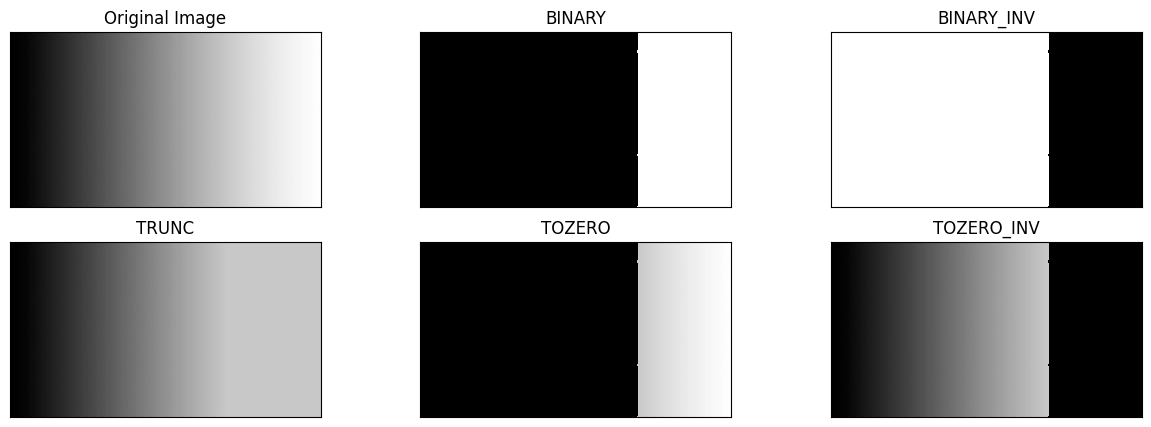

In [42]:
filename = folder + 'gradient.jpg'
img = cv.imread(filename, 0)     # dibaca sebagai grayscale
thresh = 200                     # nilai threshold yang ditentukan
maxval = 255                     # nilai maksimal

print('Ukuran citra :', img.shape)
print('Intensitas   :', img.min(), 'sampai', img.max())

#1. BINARY     : piksel > thresh menjadi maxval, selain itu 0
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)

#2. BINARY_INV : piksel > thresh menjadi 0, selain itu maxval
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)

#3. TRUNC      : piksel > thresh menjadi thresh, selain itu nilai asli tetap
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)

#4. TOZERO     : piksel > thresh nilai asli tetap, selain itu 0
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)

#5. TOZERO_INV : piksel > thresh menjadi 0, selain itu nilai asli tetap
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize = (15,5))
for i in range(len(images)):
  plt.subplot(2,3,i+1),plt.imshow(images[i],'gray', vmin=0, vmax=255, interpolation='nearest')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])
plt.show()

# **Program Adaptive Threshold**

Dimensi matriks citra: (423, 419)


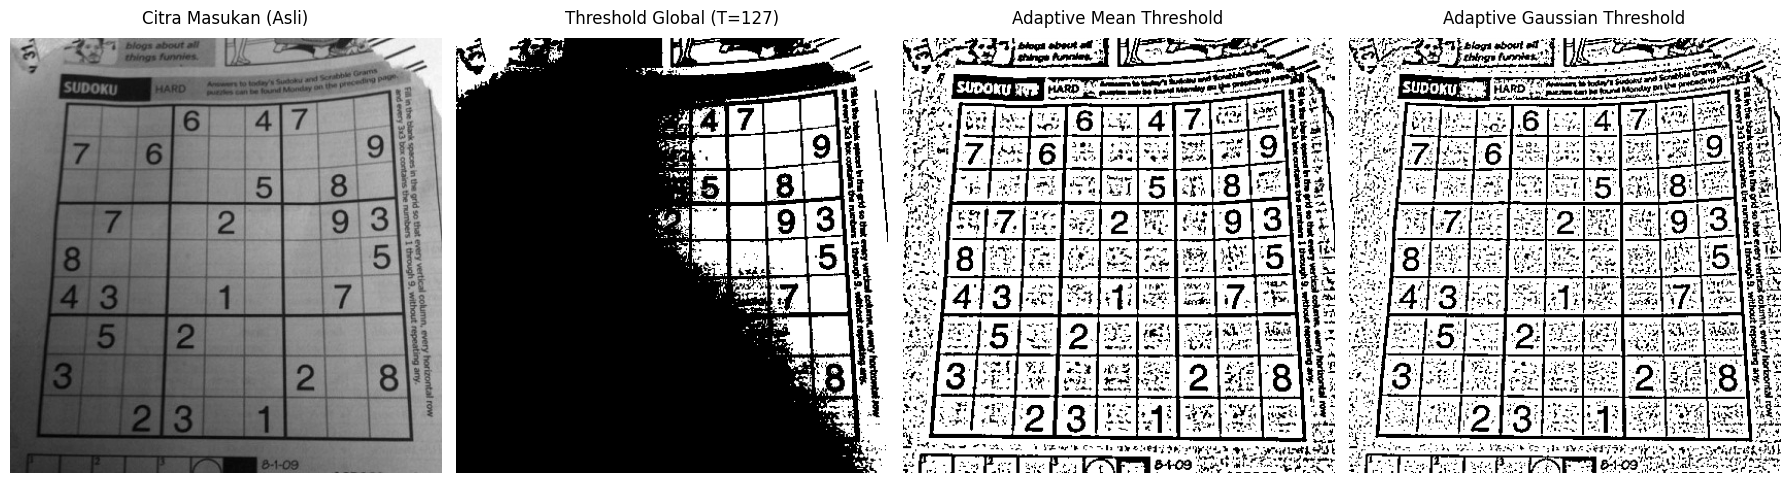

In [43]:
# Mendefinisikan path menuju file citra
path_berkas = folder + 'sudoku-original.jpg'

# Membaca citra dan langsung mengubahnya ke format derajat keabuan (grayscale)
citra_abuan = cv.imread(path_berkas, cv.IMREAD_GRAYSCALE)

# Inisialisasi parameter yang dibutuhkan untuk thresholding
ambang_batas = 127       # Nilai ambang statis untuk perbandingan
ukuran_jendela = 11      # Dimensi area lokal (11x11)
konstanta_c = 2          # Faktor pengurang dari nilai rata-rata
nilai_sigma = 2          # Nilai simpangan baku untuk distribusi Gaussian

print('Dimensi matriks citra:', citra_abuan.shape)

# Membuat citra biner menggunakan threshold global
thresh_global = np.where(citra_abuan > ambang_batas, 255, 0).astype(np.uint8)

def buat_kernel_mean(ukuran):
    """
    Menghasilkan matriks kernel untuk filter rata-rata (mean).
    Semua elemen bernilai sama dan dinormalisasi.
    """
    bobot = 1.0 / (ukuran * ukuran)
    matriks_kernel = np.ones((ukuran, ukuran), dtype=np.float64) * bobot
    return matriks_kernel

def buat_kernel_gaussian(ukuran, sigma):
    """
    Menghasilkan matriks kernel berbobot distribusi Gaussian.
    """
    radius = ukuran // 2
    rentang_titik = np.arange(-radius, radius + 1)
    grid_x, grid_y = np.meshgrid(rentang_titik, rentang_titik)

    # Kalkulasi nilai Gaussian 2D
    komponen_eksponen = np.exp(-(grid_x**2 + grid_y**2) / (2 * sigma**2))

    # Normalisasi agar total elemen matriks sama dengan 1
    kernel_ternormalisasi = komponen_eksponen / komponen_eksponen.sum()
    return kernel_ternormalisasi

def terapkan_konvolusi(citra_input, kernel_filter):
    """
    Melakukan operasi konvolusi 2D secara manual pada citra.
    """
    tinggi_citra, lebar_citra = citra_input.shape
    dimensi_k = kernel_filter.shape[0]
    batas_pad = dimensi_k // 2

    # Menerapkan edge padding untuk menangani piksel di area tepi
    citra_terpad = np.pad(citra_input.astype(np.float64), batas_pad, mode='edge')
    citra_hasil = np.zeros((tinggi_citra, lebar_citra), dtype=np.float64)

    # Melakukan perkalian dan penjumlahan elemen (sliding window)
    for baris in range(dimensi_k):
        for kolom in range(dimensi_k):
            citra_hasil += kernel_filter[baris, kolom] * citra_terpad[baris:baris + tinggi_citra, kolom:kolom + lebar_citra]

    return citra_hasil

mean_lokal = np.round(terapkan_konvolusi(citra_abuan, buat_kernel_mean(ukuran_jendela)))
batas_mean = mean_lokal - konstanta_c
thresh_adaptif_mean = np.where(citra_abuan > batas_mean, 255, 0).astype(np.uint8)

gaussian_lokal = np.round(terapkan_konvolusi(citra_abuan, buat_kernel_gaussian(ukuran_jendela, nilai_sigma)))
batas_gaussian = gaussian_lokal - konstanta_c
thresh_adaptif_gaussian = np.where(citra_abuan > batas_gaussian, 255, 0).astype(np.uint8)

judul_plot = [
    'Citra Masukan (Asli)',
    f'Threshold Global (T={ambang_batas})',
    'Adaptive Mean Threshold',
    'Adaptive Gaussian Threshold'
]

# Menggunakan tuple untuk menampung hasil pemrosesan
kumpulan_citra = (citra_abuan, thresh_global, thresh_adaptif_mean, thresh_adaptif_gaussian)

fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))
for indeks, ax in enumerate(axes):
    ax.imshow(kumpulan_citra[indeks], cmap='gray')
    ax.set_title(judul_plot[indeks], fontsize=12, pad=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

# **Membuat Otsu Thresholding tanpa menggunakan Library**

In [44]:
lena = cv.imread(folder + 'lena.jpg', 0)                       # Lena grayscale (0-255)
lena_lc = np.round(85 + lena.astype(np.float64) * (108 - 85) / 255).astype(np.uint8)
cv.imwrite(folder + 'lena_gs_lc2.jpg', lena_lc, [cv.IMWRITE_JPEG_QUALITY, 100])

print('Intensitas lena.jpg (grayscale) :', lena.min(), 'sampai', lena.max())
print('Intensitas lena_gs_lc2.jpg      :', lena_lc.min(), 'sampai', lena_lc.max(),
      '(' + str(len(np.unique(lena_lc))) + ' level)')

Intensitas lena.jpg (grayscale) : 0 sampai 255
Intensitas lena_gs_lc2.jpg      : 85 sampai 108 (24 level)


In [45]:
filename = (folder + 'lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

In [46]:
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:      # koreksi: lewati t yang membuat salah satu kelas kosong
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray >= final_thresh] = 255   # koreksi: '>' diganti '>=' (kelas foreground = piksel >= t)
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

In [47]:
otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

96


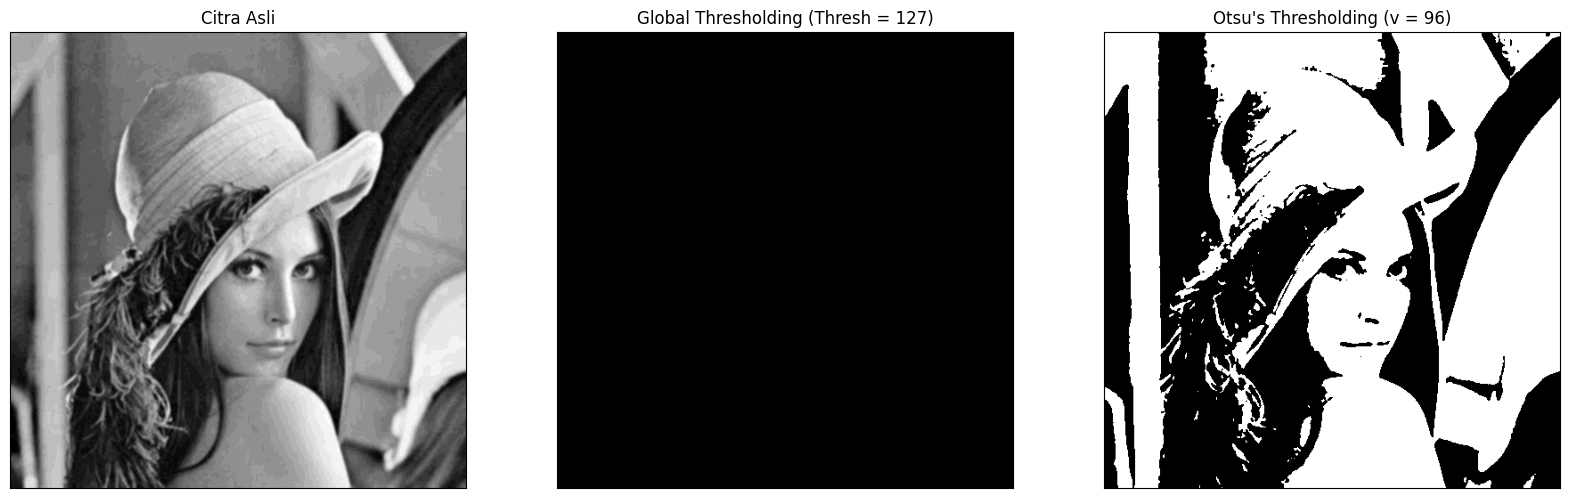

In [48]:
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

# **Membuat Otsu Thresholding menggunakan Library**

In [49]:
# Dengan Library
filename = (folder + 'lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh = 127

ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
ret2,th2 = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

/tmp/ipykernel_6425/3876882978.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [50, 200])


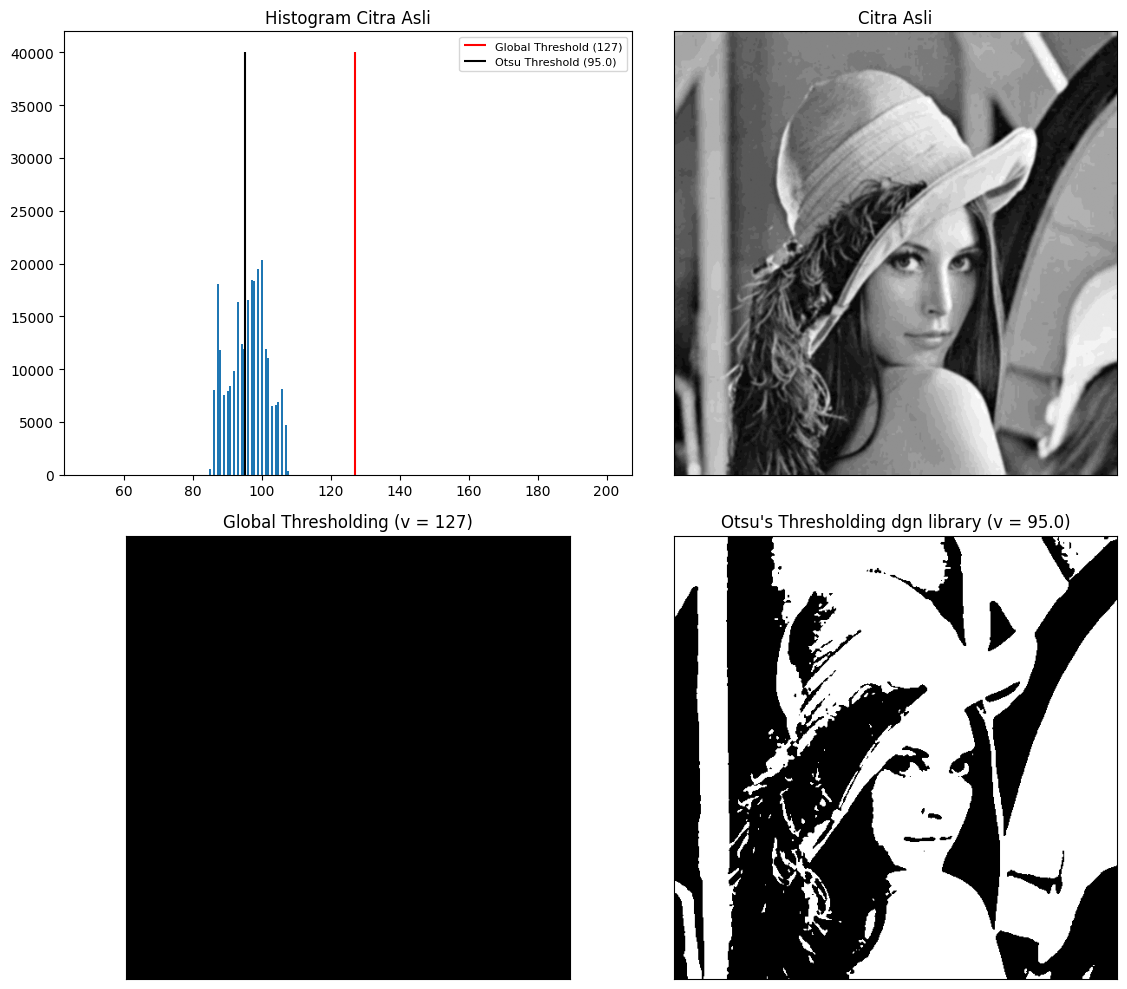

In [50]:
x = "Otsu's Thresholding dgn library (v = " + str(ret2) + ")"
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize=(12, 10))

# Subplot 1: Histogram Citra Asli dengan rentang 50 sampai 200
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [50, 200])
plt.vlines(ret, 0, 40000, colors='red', label='Global Threshold (127)')   # Garis merah untuk global threshold
plt.vlines(ret2, 0, 40000, colors='black', label=f'Otsu Threshold ({ret2})') # Garis hitam untuk Otsu
plt.title('Histogram Citra Asli')
plt.legend(loc='upper right', fontsize=8)

# Perulangan untuk menampilkan ketiga citra (Citra Asli, Global Threshold, dan Otsu)
for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

# **Membandingkan hasil Otsu manual dengan Otsu library.**

In [51]:
print('Threshold Otsu manual  :', otsu_thresh, '-> foreground = piksel >=', otsu_thresh)
print('Threshold Otsu library :', ret2, '-> foreground = piksel >', int(ret2))
print('Jumlah piksel berbeda  :', np.sum(otsu_biner != th2), 'dari', blur.size, 'piksel')

Threshold Otsu manual  : 96 -> foreground = piksel >= 96
Threshold Otsu library : 95.0 -> foreground = piksel > 95
Jumlah piksel berbeda  : 0 dari 262144 piksel


**Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?**

Intensitas minimum citra : 85
Intensitas maksimum citra: 108
Jumlah piksel > 127      : 0 (Ini membuktikan mengapa hasil Global Threshold hitam semua)


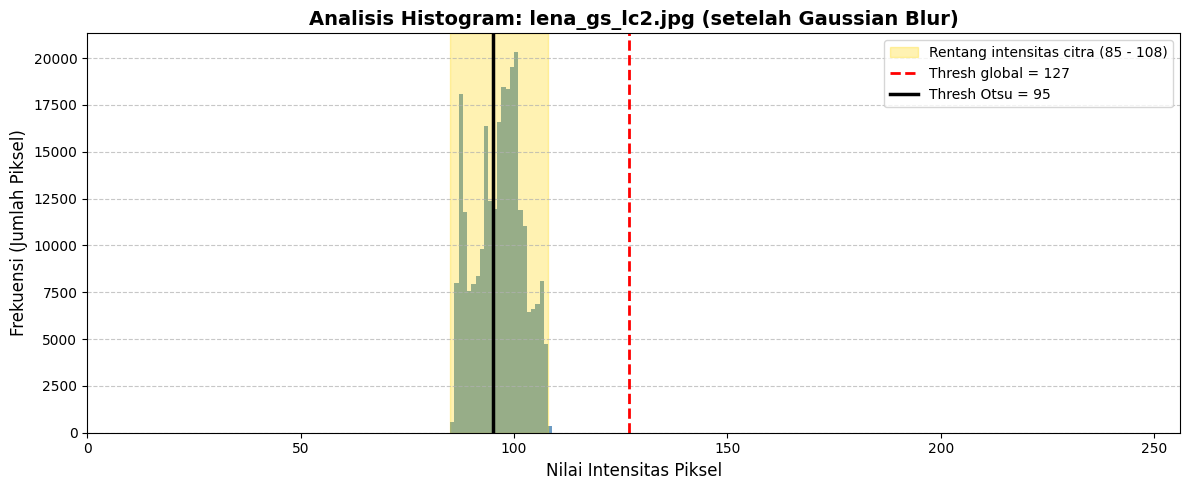

In [52]:
# Menampilkan informasi statistik intensitas piksel citra
print(f"Intensitas minimum citra : {blur.min()}")
print(f"Intensitas maksimum citra: {blur.max()}")
print(f"Jumlah piksel > 127      : {np.sum(blur > 127)} (Ini membuktikan mengapa hasil Global Threshold hitam semua)")

plt.figure(figsize=(12, 5))

plt.hist(blur.ravel(), bins=256, range=[0, 256], color='steelblue', alpha=0.8)

plt.axvspan(blur.min(), blur.max(), color='gold', alpha=0.3,
            label=f'Rentang intensitas citra ({blur.min()} - {blur.max()})')

plt.axvline(127, color='red', linestyle='--', linewidth=2,
            label='Thresh global = 127')

plt.axvline(ret2, color='black', linestyle='-', linewidth=2.5,
            label=f'Thresh Otsu = {int(ret2)}')

plt.title('Analisis Histogram: lena_gs_lc2.jpg (setelah Gaussian Blur)', fontsize=14, fontweight='bold')
plt.xlabel('Nilai Intensitas Piksel', fontsize=12)
plt.ylabel('Frekuensi (Jumlah Piksel)', fontsize=12)

plt.xlim([0, 256])

# Menampilkan legenda dan grid horisontal untuk kemudahan pembacaan
plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

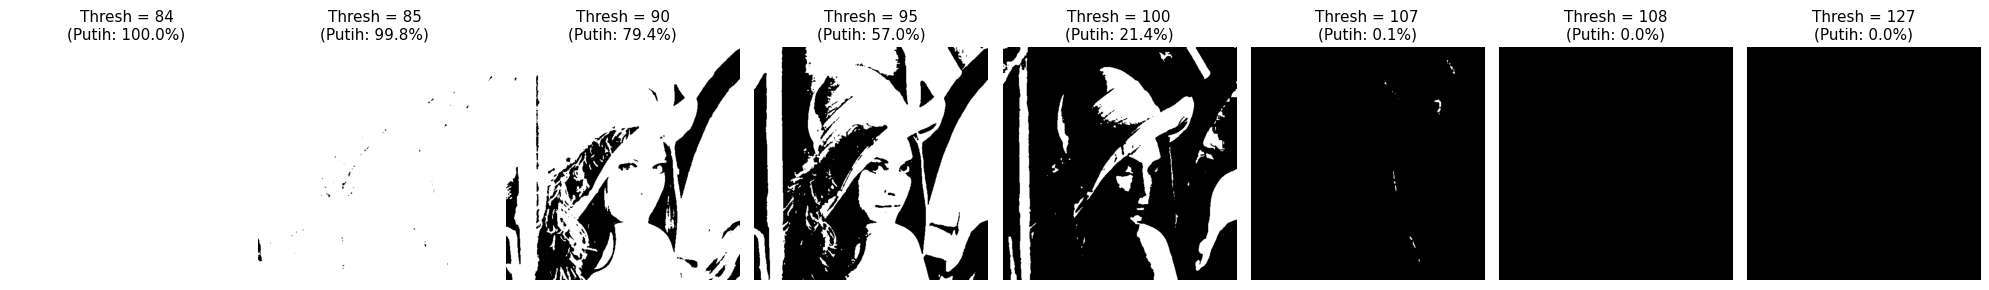

In [53]:
daftar_thresh = [84, 85, 90, int(ret2), 100, 107, 108, 127]

plt.figure(figsize=(20, 4.5))

for i, T in enumerate(daftar_thresh):
    hasil = np.where(blur > T, 255, 0).astype(np.uint8)

    persen_putih = np.mean(hasil == 255) * 100

    # Menampilkan hasil pada subplot
    plt.subplot(1, len(daftar_thresh), i + 1)
    plt.imshow(hasil, cmap='gray', vmin=0, vmax=255)

    plt.title(f'Thresh = {T}\n(Putih: {persen_putih:.1f}%)', fontsize=11)
    plt.axis('off')  # Menghilangkan garis sumbu X dan Y

plt.tight_layout()
plt.show()

**Analisis Penyebab Citra Menjadi Hitam Total**

1. Berdasarkan analisis histogram, citra `lena_gs_lc2.jpg` tergolong sebagai citra dengan kontras sangat rendah (*low contrast*). Seluruh intensitas derajat keabuan pikselnya terkumpul secara sempit pada rentang 85 hingga 108. Operasi *Binary Thresholding* bekerja dengan aturan: piksel bernilai $> thresh$ diubah menjadi 255 (putih), sedangkan sisanya menjadi 0 (hitam). Karena garis ambang batas ditetapkan pada angka 127—yang berada jauh di luar rentang maksimum intensitas piksel (108)—maka tidak ada satu pun piksel yang melampaui batas tersebut. Akibatnya, keseluruhan piksel dievaluasi sebagai $\le 127$ dan dipaksa menjadi 0, menghasilkan citra hitam total.

2. **Penentuan Angka Ambang Batas (Thresh) Ideal**
Agar objek pada citra tetap dapat dikenali, nilai *threshold* harus diletakkan tepat di dalam rentang intensitas citra (di antara 85 dan 108) sehingga histogram berhasil dipecah menjadi bagian *foreground* dan *background*. Berikut adalah rincian perilakunya:

    * **$T \ge 108$:** Seluruh piksel bernilai $\le T$, sehingga citra kembali menjadi hitam total.
    * **$T \le 84$:** Seluruh piksel bernilai $> T$, sehingga citra berubah menjadi putih total.
    * **Batas Ekstrem ($T = 85$ atau $T = 107$):** Menghasilkan citra yang hampir didominasi satu warna (99,8% putih atau 0,1% putih) karena garis pembagi berada tepat di ujung kurva histogram.
    * **Rentang Visibilitas ($T \approx 90 - 100$):** Fitur utama citra mulai terlihat jelas, dengan proporsi piksel putih bergeser seimbang dari 79,4% hingga 21,4%.
    * **Titik Optimal (Otsu):** Keseimbangan terbaik dicapai pada nilai ambang sekitar **95** (menggunakan pustaka) atau **96** (manual). Nilai ini secara presisi memotong bagian lembah di antara dua kelompok puncak histogram, sehingga dapat memisahkan detail wajah, topi, dan latar belakang Lena dengan sangat baik.

# **Membandingkan Hasil Otsu's dengan Global Threshold Biasa Menggunakan Image KTP**

166


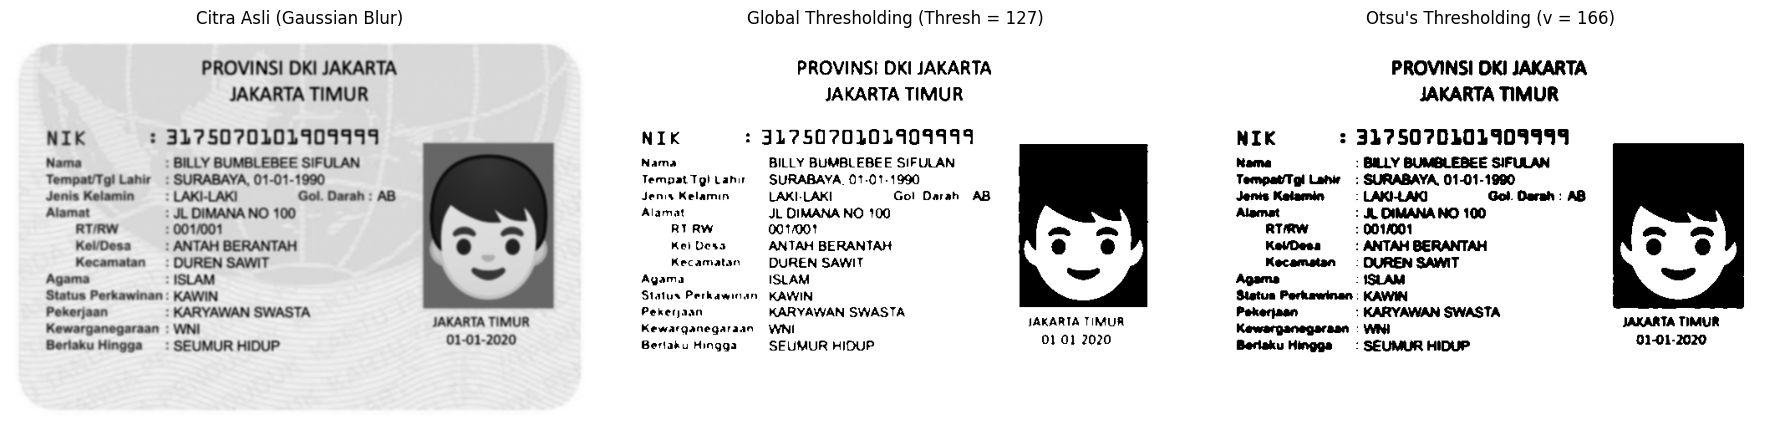

In [54]:
filename_ktp = folder + 'ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp, 0)

blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

thresh_global = 127

otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)

ret, th1_ktp = cv.threshold(blur_ktp, thresh_global, 255, cv.THRESH_BINARY)

titles_ktp = [
    'Citra Asli (Gaussian Blur)',
    f'Global Thresholding (Thresh = {thresh_global})',
    f"Otsu's Thresholding (v = {otsu_thresh_ktp})"
]
citra_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

# Mengubah figsize agar proporsional untuk 3 gambar yang sejajar horizontal
plt.figure(figsize=(18, 5))

for i in range(len(citra_ktp)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_ktp[i], cmap='gray')
    plt.title(titles_ktp[i], fontsize=12, pad=10)
    plt.axis('off')  # Menggantikan xticks([]) dan yticks([]) agar lebih ringkas

plt.tight_layout()
plt.show()

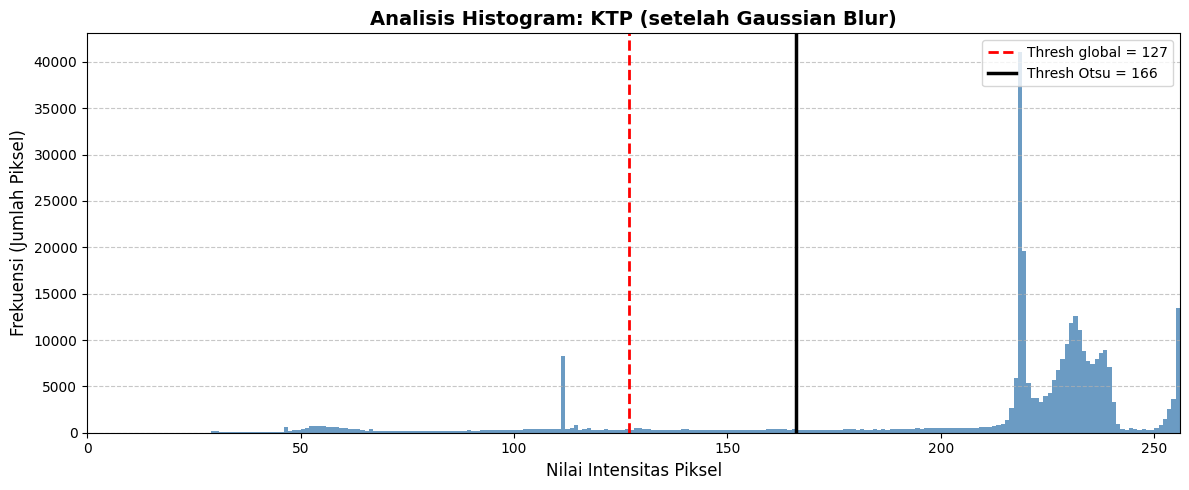

Persentase piksel hitam (Global 127): 11.5%
Persentase piksel hitam (Otsu 166)  : 15.7%


In [55]:
# Membandingkan distribusi piksel dengan citra KTP
plt.figure(figsize=(12, 5))

# Plot histogram dengan warna dan transparansi yang lebih rapi
plt.hist(blur_ktp.ravel(), bins=256, range=[0, 256], color='steelblue', alpha=0.8)

# Menambahkan garis batas threshold dengan ketebalan dan gaya yang jelas
plt.axvline(thresh, color='red', linestyle='--', linewidth=2,
            label=f'Thresh global = {thresh}')
plt.axvline(otsu_thresh_ktp, color='black', linestyle='-', linewidth=2.5,
            label=f'Thresh Otsu = {otsu_thresh_ktp}')

# Penyesuaian judul, label, dan grid
plt.title('Analisis Histogram: KTP (setelah Gaussian Blur)', fontsize=14, fontweight='bold')
plt.xlabel('Nilai Intensitas Piksel', fontsize=12)
plt.ylabel('Frekuensi (Jumlah Piksel)', fontsize=12)
plt.xlim([0, 256])

plt.legend(loc='upper right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Memperbaiki sintaks perhitungan persentase dan beralih ke f-string
persen_hitam_global = np.mean(th1_ktp == 0) * 100
persen_hitam_otsu = np.mean(otsu_biner_ktp == 0) * 100

print(f"Persentase piksel hitam (Global {thresh}): {persen_hitam_global:.1f}%")
print(f"Persentase piksel hitam (Otsu {otsu_thresh_ktp})  : {persen_hitam_otsu:.1f}%")

### **Analisis Perbandingan Hasil Segmentasi KTP (Global vs. Otsu's Thresholding)**

* **Analisis Histogram Citra KTP**
* Terdapat satu puncak distribusi utama pada kisaran intensitas **215–245**, yang merepresentasikan area latar belakang KTP (warna biru muda yang menjadi terang setelah dikonversi ke *grayscale*).
* Piksel dengan intensitas gelap (merepresentasikan teks, detail foto, dan tepian huruf) tersebar secara meluas pada rentang **40–160**.
* Algoritma Otsu secara otomatis menempatkan nilai ambang batas pada **thresh = 166**, tepat di titik lembah yang memisahkan sebaran piksel gelap dan puncak latar belakang. Sebaliknya, ambang statis **127** berada tepat di tengah-tengah sebaran piksel teks.


* **Hasil Global Thresholding (Thresh = 127)**
* Latar belakang berhasil diubah menjadi putih bersih. Namun, piksel pada area tepi huruf (yang memiliki nilai intensitas antara 127 hingga 166) ikut terkonversi menjadi putih.
* **Dampak Visual:** Karakter huruf mengalami penipisan secara signifikan. Detail karakter berukuran kecil banyak yang hilang, seperti: tanda titik dua (`:`) pada isian data, garis miring (`/`) pada "Tempat/Tgl Lahir", "RT/RW", dan "Kel/Desa", tanda hubung (`-`) pada tanggal "01-01-2020", serta tanda baca pada "Gol. Darah : AB".
* Total persentase piksel hitam (*foreground*) yang dihasilkan hanya sebesar **11,5%**.


* **Hasil Otsu's Thresholding (Thresh = 166)**
* Seluruh rentang piksel teks beserta area tepinya berhasil dikonversi menjadi hitam. Hal ini menghasilkan bentuk tulisan yang tampak lebih tebal, utuh, dan detail tanda baca kecil tetap berhasil dipertahankan.
* **Kekurangan:** Karena karakter mengalami penebalan, beberapa huruf berukuran kecil cenderung menyatu atau berdempetan. Selain itu, area pasfoto (yang aslinya memiliki latar merah gelap) terdeteksi sebagai objek tebal dan berubah menjadi blok hitam pekat.
* Total persentase piksel hitam (*foreground*) meningkat menjadi **15,7%**.


* **Kesimpulan**
* Metode Otsu terbukti lebih unggul dan adaptif karena mampu menentukan nilai ambang batas secara otomatis berdasarkan distribusi bentuk histogram citra. Pendekatan ini menghasilkan pemisahan antara teks dan latar belakang yang jauh lebih utuh dan akurat dibandingkan penetapan *Global Threshold* (127) yang ditentukan secara statis tanpa mengevaluasi histogram citra masukan.

In [56]:
# Memuat citra koin bawaan dari pustaka skimage
img = data.coins()

img_halus = gaussian(img, sigma=2, preserve_range=True)

# Menampilkan informasi dimensi dan rentang intensitas piksel menggunakan f-string
print(f"Ukuran citra coins : {img.shape}")
print(f"Intensitas piksel  : {img.min()} sampai {img.max()}")

Ukuran citra coins : (303, 384)
Intensitas piksel  : 1 sampai 252


# **Segmentasi Berbasis Region (Region Growing) pada citra data.coins() dari skimage.**

Seed Dalam koin (baris, kolom): (54, 44) | Intensitas asli: 194 | Setelah Gaussian: 175.48
Seed Latar      (baris, kolom): (90, 75) | Intensitas asli: 93 | Setelah Gaussian: 92.88
Seed Tepi koin  (baris, kolom): (54, 22) | Intensitas asli: 151 | Setelah Gaussian: 144.43


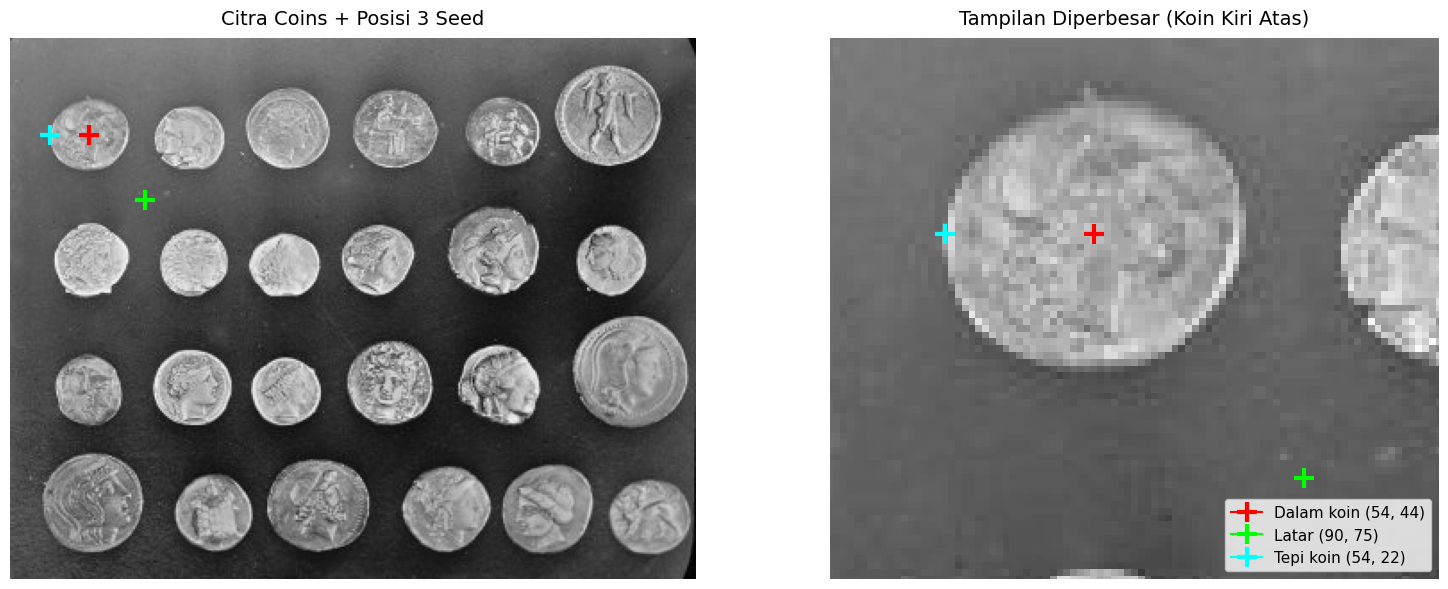

In [57]:
seeds = {
    'Dalam koin': (54, 44),
    'Latar'     : (90, 75),
    'Tepi koin' : (54, 22),
}

nilai_T = [5, 20, 60]
warna_seed = ['red', 'lime', 'cyan']

for nama, posisi in seeds.items():
    intensitas_asli = img[posisi]
    intensitas_halus = img_halus[posisi]
    print(f"Seed {nama:<10} (baris, kolom): {posisi} | Intensitas asli: {intensitas_asli} | Setelah Gaussian: {intensitas_halus:.2f}")

# Menyiapkan kanvas figur untuk visualisasi
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Citra keseluruhan beserta penanda 3 titik seed
axs[0].imshow(img, cmap='gray')
axs[0].set_title('Citra Coins + Posisi 3 Seed', fontsize=14, pad=10)

# Subplot 2: Perbesaran area citra (fokus pada koin pojok kiri atas)
axs[1].imshow(img, cmap='gray')
axs[1].set_xlim(5, 95)
axs[1].set_ylim(105, 25)  # y-axis dibalik agar sesuai dengan koordinat citra (titik 0 di atas)
axs[1].set_title('Tampilan Diperbesar (Koin Kiri Atas)', fontsize=14, pad=10)

for ax in axs:
    for (nama, (r, c)), w in zip(seeds.items(), warna_seed):
        ax.plot(c, r, marker='+', color=w, markersize=15, markeredgewidth=3, label=f"{nama} ({r}, {c})")
    ax.axis('off')

axs[1].legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

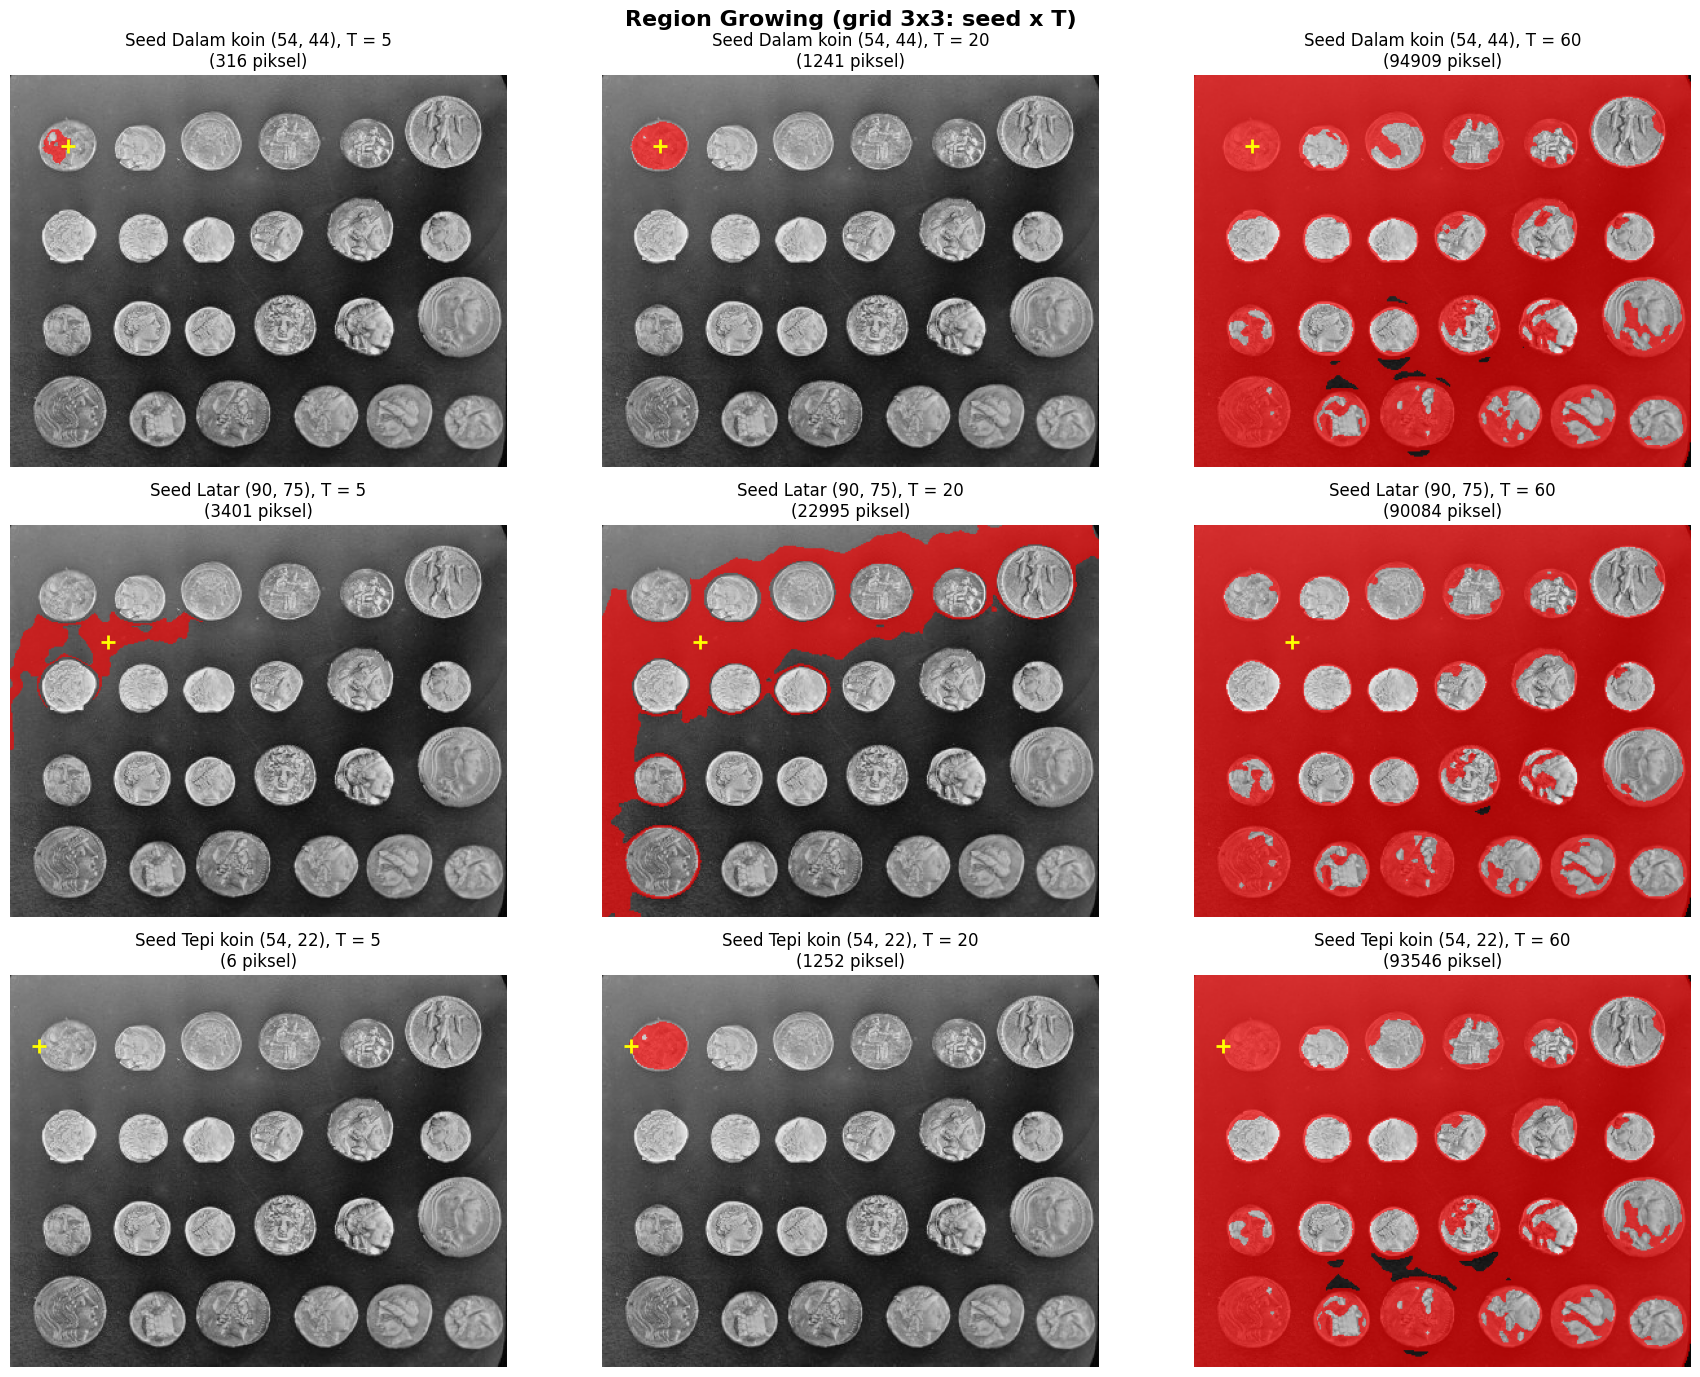

           T = 5 T = 20 T = 60
Dalam koin   316   1241  94909
Latar       3401  22995  90084
Tepi koin      6   1252  93546


In [58]:
def region_growing(citra, seed, T):
    H, W = citra.shape
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    jumlah_intensitas = float(citra[seed])   # untuk menghitung rata-rata region
    n = 1                                    # banyak piksel di dalam region
    antrean = deque([seed])
    tetangga = [(-1, -1), (-1, 0), (-1, 1),
                ( 0, -1),          ( 0, 1),
                ( 1, -1), ( 1, 0), ( 1, 1)]

    while antrean:
        y, x = antrean.popleft()
        for dy, dx in tetangga:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                rata2_region = jumlah_intensitas / n
                if abs(citra[ny, nx] - rata2_region) < T:
                    mask[ny, nx] = True
                    jumlah_intensitas += citra[ny, nx]
                    n += 1
                    antrean.append((ny, nx))
    return mask

# Menggunakan f-string untuk penamaan kolom
jumlah_piksel = pd.DataFrame(index=list(seeds.keys()), columns=[f'T = {T}' for T in nilai_T])

fig, axs = plt.subplots(3, 3, figsize=(18, 14))
for i, (nama, posisi) in enumerate(seeds.items()):
    for j, T in enumerate(nilai_T):
        mask = region_growing(img_halus, posisi, T)
        jumlah_piksel.loc[nama, f'T = {T}'] = int(mask.sum())

        tampilan = np.stack([img, img, img], axis=-1).astype(np.float64)
        tampilan[mask] = 0.35 * tampilan[mask] + 0.65 * np.array([255, 0, 0])   # region diberi warna merah

        axs[i, j].imshow(tampilan.astype(np.uint8))
        axs[i, j].plot(posisi[1], posisi[0], '+', color='yellow', markersize=10, markeredgewidth=2)

        axs[i, j].set_title(f'Seed {nama} {posisi}, T = {T}\n({mask.sum()} piksel)', fontsize=12)
        axs[i, j].axis('off')

plt.suptitle('Region Growing (grid 3x3: seed x T)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print(jumlah_piksel)

# **Menggunakan skimage.segmentation.flood()**

Hasil kode modul -> seed (121, 63) | tolerance 20 : 177 piksel
Seed (baris, kolom): (36, 43) | Intensitas: 159.000000
Toleransi  5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


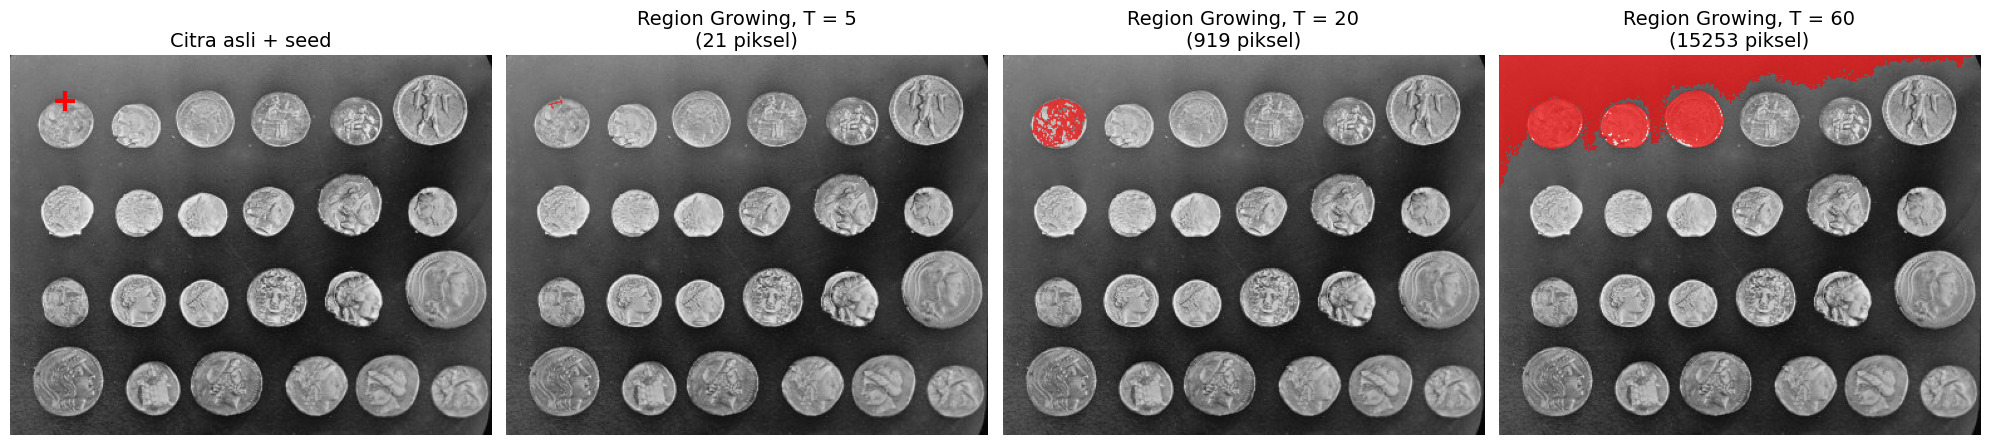

In [59]:
# Memuat citra koin bawaan dari pustaka skimage
gray = data.coins()
seed = (121, 63)          # Format: (baris, kolom)

region = flood(
    gray,
    seed_point=seed,
    tolerance=20,
    connectivity=1       # 1 berarti 4-ketetanggaan untuk citra 2D
)

print(f"Hasil kode modul -> seed {seed} | tolerance 20 : {np.sum(region)} piksel")

seed_flood = (36, 43)     # Format: (baris, kolom)
print(f"Seed (baris, kolom): {seed_flood} | Intensitas: {gray[seed_flood]:.6f}")

hasil_flood = {}
for T in nilai_T:
    hasil_flood[T] = flood(gray, seed_point=seed_flood, tolerance=T, connectivity=1)
    print(f"Toleransi {T:2d}: {np.sum(hasil_flood[T])} piksel")

fig, axs = plt.subplots(1, 4, figsize=(20, 5))

# Subplot 1: Citra asli dengan penanda titik seed
axs[0].imshow(gray, cmap='gray')
axs[0].plot(seed_flood[1], seed_flood[0], 'r+', markersize=15, markeredgewidth=3)
axs[0].set_title('Citra asli + seed', fontsize=14)
axs[0].axis('off')

# Subplot 2-4: Menampilkan citra hasil segmentasi multi-toleransi
for i, T in enumerate(nilai_T):
    tampilan = np.stack([gray, gray, gray], axis=-1).astype(np.float64)

    tampilan[hasil_flood[T]] = 0.35 * tampilan[hasil_flood[T]] + 0.65 * np.array([255, 0, 0])

    axs[i + 1].imshow(tampilan.astype(np.uint8))
    axs[i + 1].set_title(f"Region Growing, T = {T}\n({np.sum(hasil_flood[T])} piksel)", fontsize=14)
    axs[i + 1].axis('off')

plt.tight_layout()
plt.show()

# **Segmentasi Warna pada Image ktp_fulan.jpg**

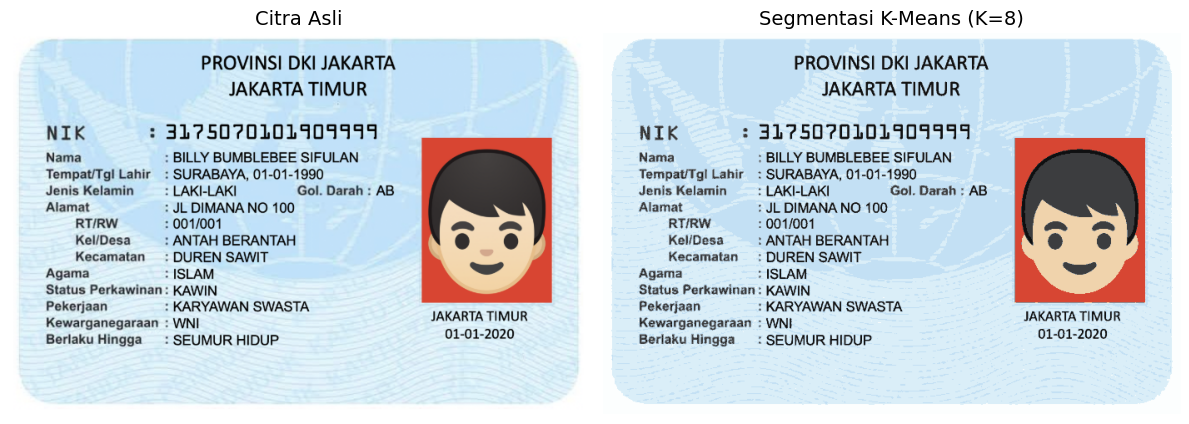

In [60]:
from sklearn.cluster import KMeans

filename = folder + 'ktp_fulan.jpg'

img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 8

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Citra Asli', fontsize=14)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_img)
plt.title(f'Segmentasi K-Means (K={k})', fontsize=14)
plt.axis('off')

plt.tight_layout()
plt.show()

In [61]:
centers_hsv = cv.cvtColor(centers.reshape(1, k, 3), cv.COLOR_RGB2HSV).reshape(k, 3)

H = centers_hsv[:, 0].astype(int)
S = centers_hsv[:, 1].astype(int)
V = centers_hsv[:, 2].astype(int)

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

print(f"Cluster yang termasuk warna biru: {kelompok_biru[0]}")

tabel_cluster = pd.DataFrame({
    'R': centers[:, 0],
    'G': centers[:, 1],
    'B': centers[:, 2],
    'H': H,
    'S': S,
    'V': V,
    'Jumlah Piksel': np.bincount(labels, minlength=k),
    'Kategori Biru?': ['Ya' if i in kelompok_biru[0] else 'Tidak' for i in range(k)]
})

tabel_cluster.index.name = 'Cluster'

tabel_cluster

Cluster yang termasuk warna biru: [1 4 7]


,R,G,B,H,S,V,Jumlah Piksel,Kategori Biru?
Cluster,,,,,,,,
0,60,61,63,110,12,63,16966,Tidak
1,218,238,248,100,31,248,123331,Ya
2,215,70,51,3,195,215,10912,Tidak
3,15,16,17,105,30,17,8526,Tidak
4,138,149,157,103,31,157,9341,Ya
5,240,211,172,17,72,240,8799,Tidak
6,252,254,254,90,2,254,25242,Tidak
7,195,224,244,102,51,244,114735,Ya


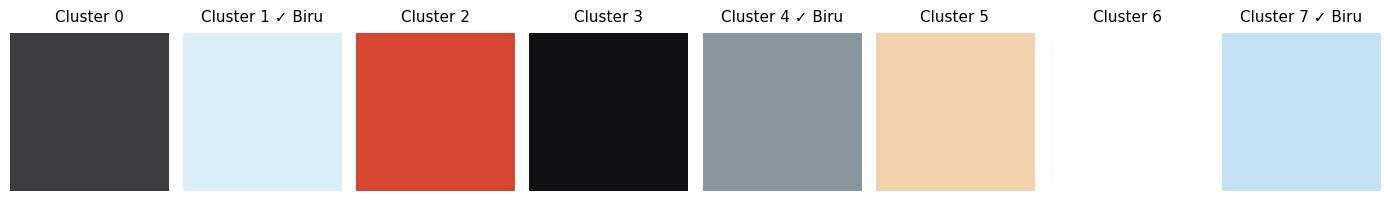

In [62]:
plt.figure(figsize=(14, 2.5))

for i in range(k):
    plt.subplot(1, k, i + 1)
    warna_blok = np.full((10, 10, 3), centers[i], dtype=np.uint8)
    plt.imshow(warna_blok)
    tanda = ' ✓ Biru' if i in kelompok_biru[0] else ''
    plt.title(f"Cluster {i}{tanda}", fontsize=11, pad=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [63]:
mask_biru = np.isin(labels, kelompok_biru[0]).reshape(img.shape[:2])

hanya_biru = np.zeros_like(img)

hanya_biru[mask_biru] = img[mask_biru]

persentase_biru = mask_biru.mean() * 100

print(f"Persentase piksel biru: {persentase_biru:.1f}%")

Persentase piksel biru: 77.8%


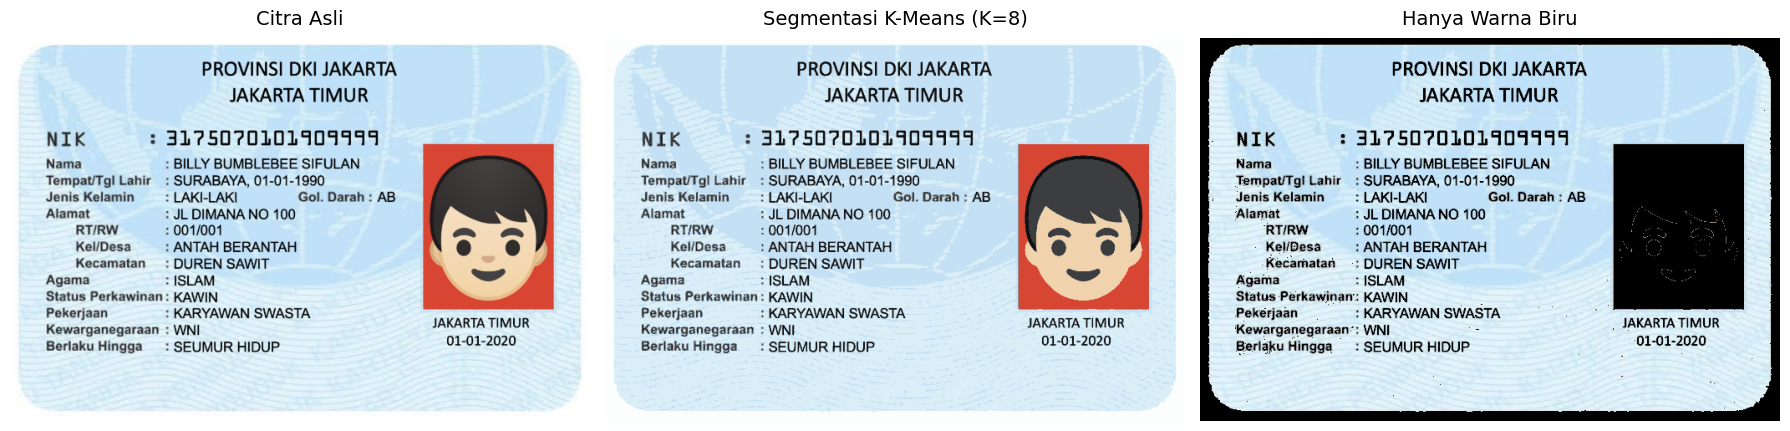

In [64]:
plt.figure(figsize=(18, 5))

# Subplot 1: Citra Asli KTP
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title('Citra Asli', fontsize=14, pad=10)
plt.axis('off')

# Subplot 2: Hasil Segmentasi K-Means
plt.subplot(1, 3, 2)
plt.imshow(segmented_img)
plt.title(f'Segmentasi K-Means (K={k})', fontsize=14, pad=10)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hanya_biru)
plt.title('Hanya Warna Biru', fontsize=14, pad=10)
plt.axis('off')

plt.tight_layout()
plt.show()

# **Tugas Praktikum Kelompok**

In [65]:
# Instalasi Tesseract OCR
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [66]:
import pytesseract
from pytesseract import Output

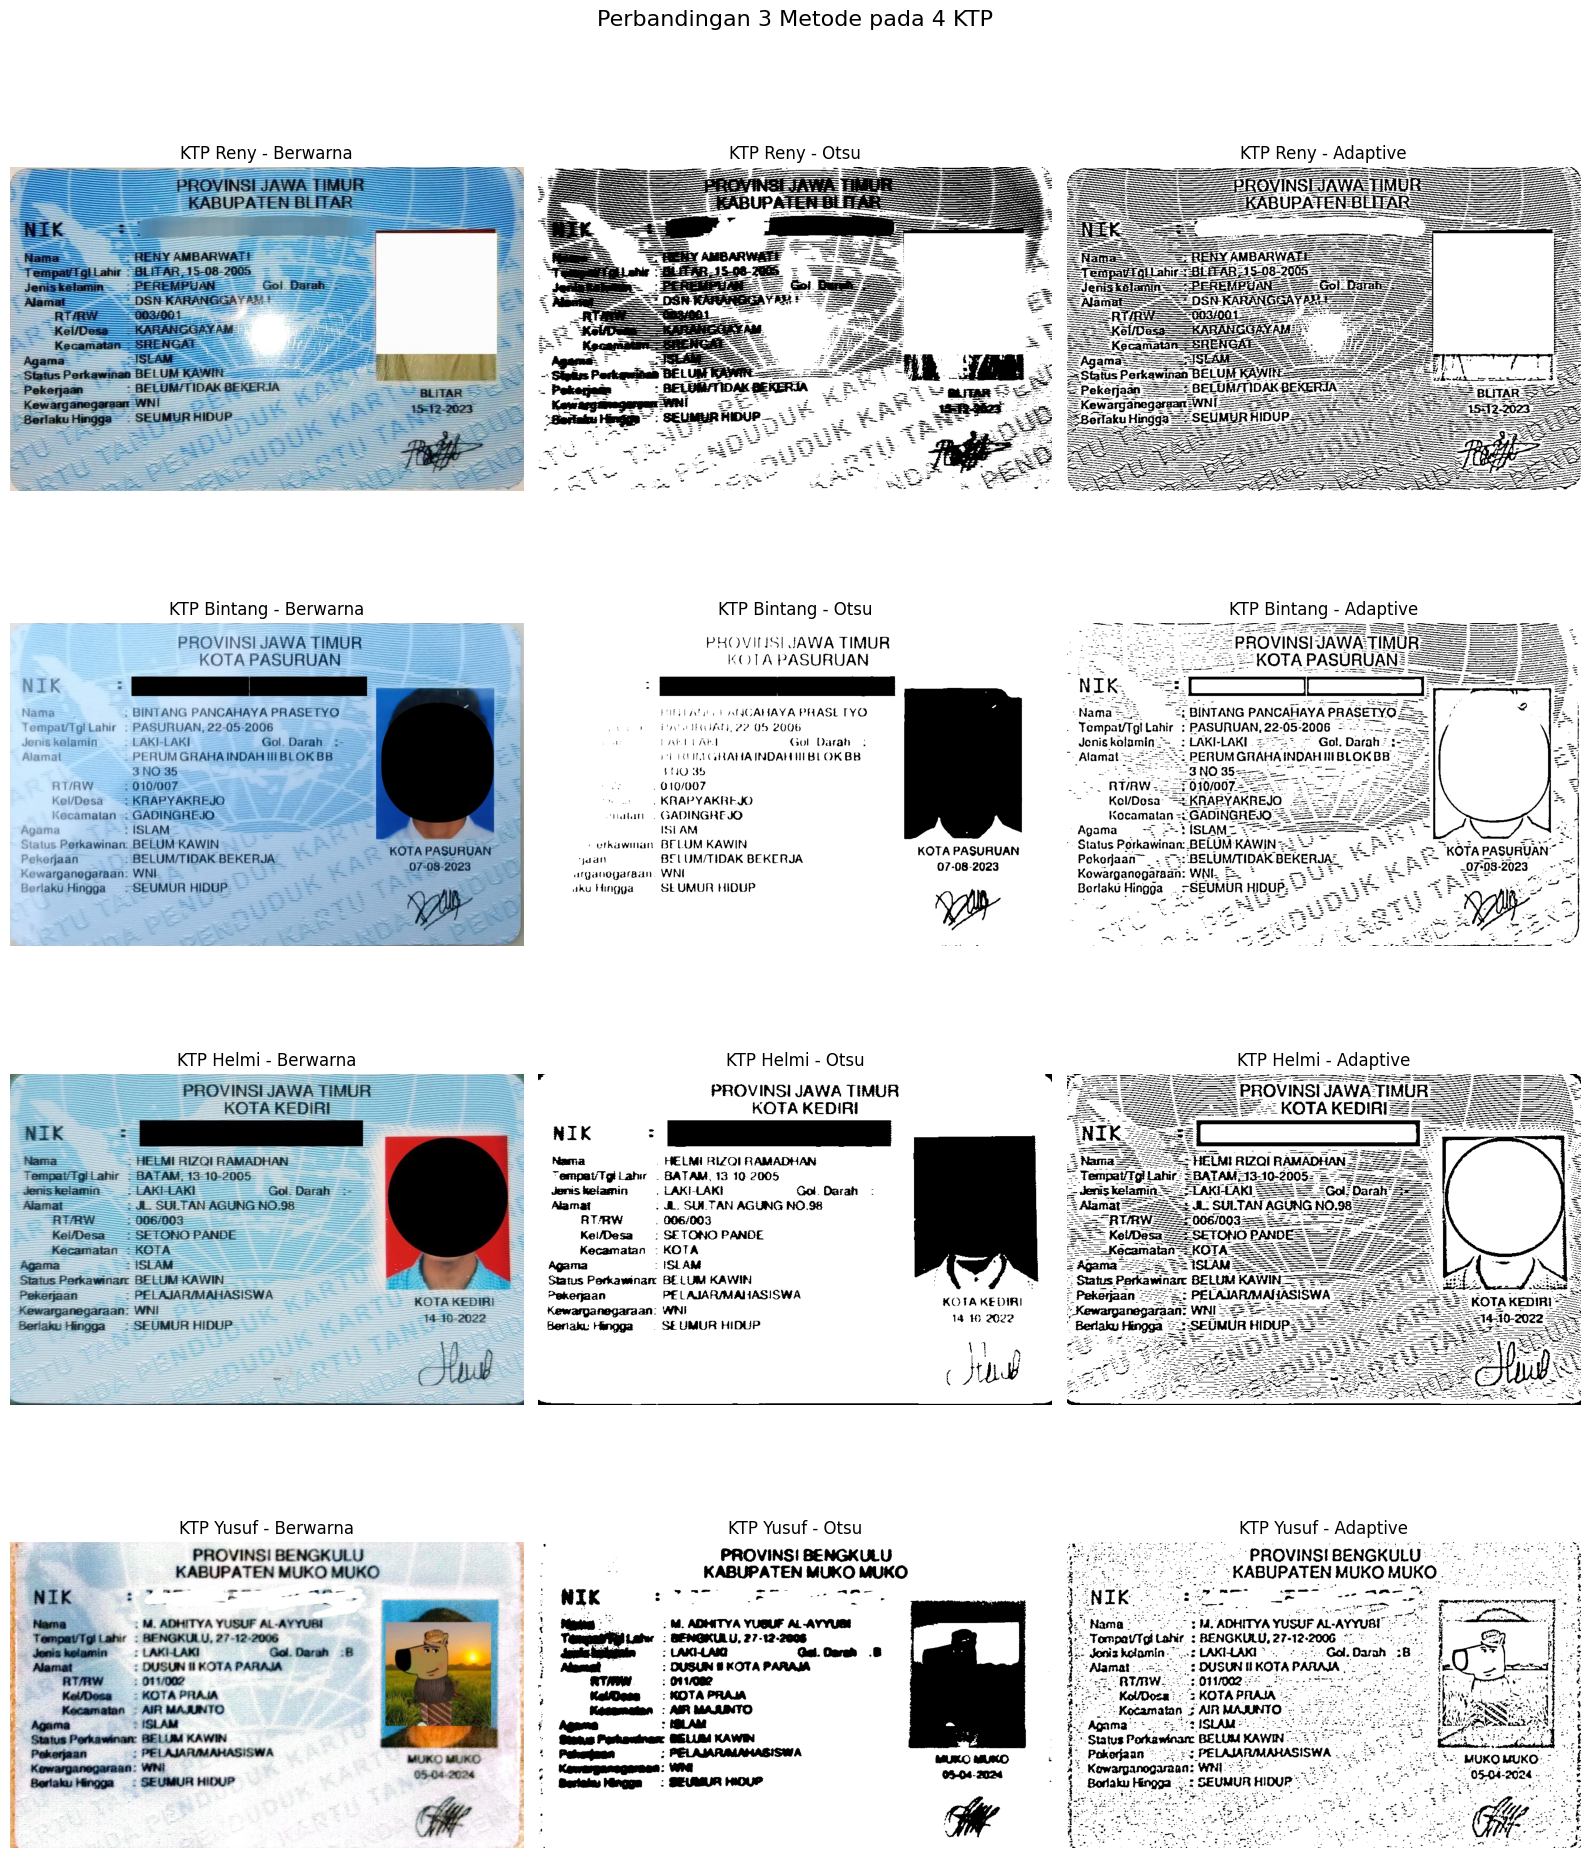

In [67]:
# Daftar nama pemilik KTP sesuai dengan penamaan file Anda
daftar_nama = ['reny', 'bintang', 'helmi', 'yusuf']
judul = ['Berwarna', 'Otsu', 'Adaptive']

# Membuat figure matplotlib dengan grid 4 baris dan 3 kolom
# Ukuran disesuaikan agar gambar tidak terlalu kecil
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(16, 20))
fig.suptitle('Perbandingan 3 Metode pada 4 KTP', fontsize=16)

# Loop untuk setiap nama KTP
for baris, nama in enumerate(daftar_nama):
    # Sesuaikan path direktori dengan path Google Drive Anda
    path_gambar = f'/content/drive/MyDrive/PCVK 2026/Images/ktp_{nama}.jpeg'

    # Membaca citra
    ktp = cv.imread(path_gambar)

    if ktp is None:
        print(f"Peringatan: Gambar untuk {nama} tidak ditemukan di path: {path_gambar}")
        continue

    # Proses konversi dan filter (Sama seperti kode asli)
    gray_ktp = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
    blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)

    # Thresholding
    ret, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                          cv.THRESH_BINARY, 25, 10)

    # List citra yang akan ditampilkan
    citra_uji = [cv.cvtColor(ktp, cv.COLOR_BGR2RGB), citra_otsu, citra_adaptive]

    # Menampilkan 3 variasi gambar untuk 1 KTP pada baris yang sesuai
    for kolom in range(3):
        ax = axes[baris, kolom]
        cmap = None if kolom == 0 else 'gray'
        ax.imshow(citra_uji[kolom], cmap=cmap)
        # Menambahkan nama orang pada judul setiap gambar
        ax.set_title(f"KTP {nama.capitalize()} - {judul[kolom]}")
        ax.axis('off')

# Merapikan tata letak agar tidak berdempetan
plt.tight_layout()
plt.subplots_adjust(top=0.95) # Memberi ruang untuk suptitle
plt.show()

In [68]:
# ----- Langkah 2: pembacaan teks dengan pytesseract.image_to_string() -----
konfigurasi = '--psm 6'
bahasa = 'ind'

# Tentukan ulang daftar nama dan judul
daftar_nama = ['reny', 'bintang', 'helmi', 'yusuf']
judul = ['Berwarna', 'Otsu', 'Adaptive']

# Menggunakan dictionary bersarang (nested dictionary) untuk menyimpan semua hasil
hasil_teks = {}

for pemilik in daftar_nama:
    print(f"\n{'#'*15} MEMBACA OCR KTP: {pemilik.upper()} {'#'*15}\n")

    # 1. Kita perlu memproses ulang gambarnya di sini agar citra_uji diperbarui untuk tiap orang
    path_gambar = f'/content/drive/MyDrive/PCVK 2026/Images/ktp_{pemilik}.jpeg'
    ktp = cv.imread(path_gambar)

    if ktp is None:
        continue

    gray_ktp = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
    blur_ktp = cv.GaussianBlur(gray_ktp, (3, 3), 0)
    _, citra_otsu = cv.threshold(blur_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    citra_adaptive = cv.adaptiveThreshold(blur_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 25, 10)

    citra_uji = [cv.cvtColor(ktp, cv.COLOR_BGR2RGB), citra_otsu, citra_adaptive]

    # 2. Proses OCR untuk ke-3 metode (Berwarna, Otsu, Adaptive)
    hasil_teks[pemilik] = {} # Buat sub-dictionary untuk menyimpan teks per orang

    for nama_metode, citra in zip(judul, citra_uji):
        teks = pytesseract.image_to_string(citra, lang=bahasa, config=konfigurasi)
        hasil_teks[pemilik][nama_metode] = teks

        print('=' * 10, f"{nama_metode} - KTP {pemilik.capitalize()}", '=' * 10)
        print(teks)
        print()


############### MEMBACA OCR KTP: RENY ###############

========== Berwarna - KTP Reny ==========
5—cee #1. cw zr -
5Z-—e AAA AA
—:—e-: —5— DAY I NS“ A NYA —- —
5 — ABU AE BE AR
aa Pa ee aa AA
— JP 5 ——— 2 5 — 5
5—.—— —— 3 —————-
— — 5 |—————
— ——— To ——— FP
JT &&L&&& 55 ——
we Pr 5 -
— Nama — — —HENYAMBARWATE- —————— Te
——ws-—————— A5 —.—
STempargi Lahi SBL PFAR 15-03-2005 3 ——
Pa — me wi —
jera — PEREMPUAN ——— Gol Darah —
aa ea aa wwe -
—J5—— — ——ew —
Alama— — “DSN KARANGAY II FF
— AA 930p — 5 —
— RAM 03001 —— A5 PP
—— Kel/Dese —KARANGGAYAM Ea | PF
11 AA ES 5 FA
“Agama SAM — PE FA
A3 5 AA 2 AS
—Status Perkawinan BELUM KAWI-———.-——— 5
Pokana — BELUM DAK BEKERIA 3 ge
“Kewarganegaraan WNI 5 5. 22 2023 —
2Beriaku Hingga - SEUMURHIDUP —— 5. 55
AAA AA
SA — AA AA Le 5 5—ya
SA AK AAA AE
Ae AA 2 EA A
PA BA SP AA
5 ti AA #-w—-——6—-———
SE — RAT ———— “AK KKS Sa ——
AE AA Ae ———ara


========== Otsu - KTP Reny ==========
- en —- —-  £
Ba SUPATENG ,
— -——— ——— AP
FI “ga ————....
—. vw — PP —— aus -
